# Medido frente a modelado en los diez muestreos: la compuerta de expectativas, los residuos de tonelaje y la potencia que no sigue

**Pregunta:** ¿Cuáles de las cantidades que informa el motor para los muestreos del HP500 reproduce, cuáles no, y sigue el motor vivo entregando el documento de columna vertebral versionado?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- aplicar la compuerta de expectativas de los casos reales, cuyos rangos vienen de la medición y de relaciones de chancado y no del motor;
- leer los residuos de tonelaje frente a la abertura y frente al f80 de alimentación, y decir cuál captura el modelo;
- comparar la potencia modelada, en sus dos formas, con la potencia medida, y leer el resultado negativo;
- confirmar que los resultados vivos del motor son el documento de columna vertebral versionado.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones agregan la compuerta de expectativas y las definiciones de los casos reales, las dos formas de potencia del motor y el constructor de la columna vertebral, a las del notebook 01.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.capacity import bond_power, calibrated_power
from pipeline.model.crusher.hp500 import HP500_BLEND_WI_KWH_T
from pipeline.cases import hp500_cases
from pipeline.oracles import bond_energy_kwh_t
from pipeline.core.expect import check, ExpectationError
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500 otra vez, y el documento de columna vertebral versionado que el pipeline escribió desde ellos. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv` y `data/derived/hp500/backbone.json`, este último con los valores medidos y los resultados del motor de cada muestreo (contrato `hp500-backbone`).

La celda lee ambos y corre el motor calibrado en los diez muestreos.

In [2]:
# Lea los muestreos y la columna vertebral versionada, y corra el motor calibrado en cada muestreo
surveys = read_surveys().accepted
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
measured_q = np.array([s.feed_tph for s in surveys])
measured_kw = np.array([s.power_kw for s in surveys])
print("muestreos:", len(surveys), "| versión del motor versionada:", committed["engine_version"])

muestreos: 10 | versión del motor versionada: 0.09.003


## Método

**Paso 1, la compuerta de expectativas.** Cada caso real lleva un rango para tres resultados, escrito a partir de la medición y de relaciones de chancado, nunca del valor del motor (`cases/hp500_cases.py`): el tonelaje a menos de 29 por ciento del flujo de alimentación medido, el P80 entre 0,35 y 1,1 veces la abertura (la relación de un chancador alimentado atorado de Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193), y una razón de reducción entre 1,8 y 4. La celda construye los diez casos, aplica `check` a los resultados vivos y lista el veredicto de cada uno.

In [3]:
# Aplique la compuerta de expectativas de cada caso real al resultado vivo del motor
verdicts = {}
for case, r in zip(hp500_cases.build(surveys), runs):
    live = {"throughput_tph": r.throughput_tph, "p80_mm": r.p80, "reduction_ratio": r.reduction_ratio}
    try:
        check(case.id, case.expect, live)
        verdicts[case.id] = "inside"
    except ExpectationError as exc:
        verdicts[case.id] = str(exc)
print("dentro de cada rango:", sum(v == "inside" for v in verdicts.values()), "de", len(verdicts))
print({k: v for k, v in verdicts.items() if v != "inside"})

dentro de cada rango: 10 de 10
{}


**Paso 2, los residuos de tonelaje.** El residuo del muestreo $i$ es el tonelaje modelado menos el medido, en porcentaje del medido. La pregunta es qué variable lo explica. La celda calcula los residuos y la correlación del tonelaje medido con la abertura y con el f80 de alimentación, y lo mismo para el modelo, que depende solo de la abertura.

In [4]:
# Residuos de tonelaje y correlaciones del tonelaje medido y modelado con la abertura y el f80
modelled_q = np.array([r.throughput_tph for r in runs])
residual = (modelled_q - measured_q) / measured_q * 100


def corr(a, b):
    return round(float(np.corrcoef(a, b)[0, 1]), 3)


print("error medio:", round(float(residual.mean()), 2), "% | error absoluto medio:", round(float(np.abs(residual).mean()), 2), "%")
print("medido frente a abertura:", corr(measured_q, css), "| medido frente a f80:", corr(measured_q, f80), "| modelado frente a medido:", corr(modelled_q, measured_q))

error medio: -2.6 % | error absoluto medio: 11.55 %
medido frente a abertura: 0.815 | medido frente a f80: -0.086 | modelado frente a medido: 0.815


La figura dibuja los residuos contra la abertura a la izquierda y contra el f80 a la derecha, con la banda de 29 por ciento de la compuerta de expectativas.

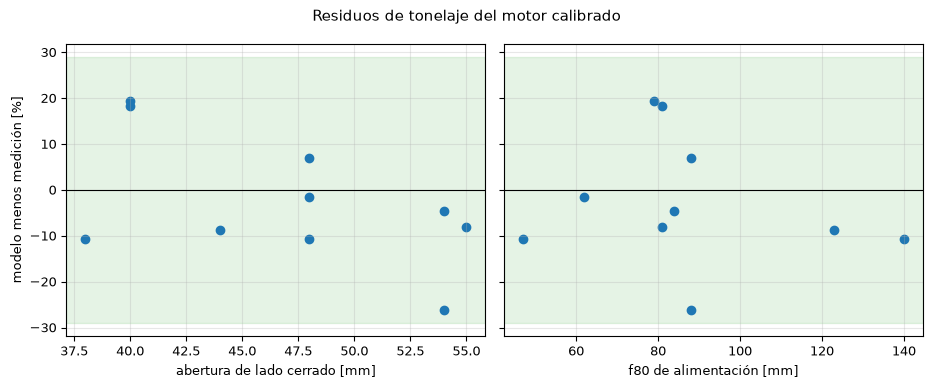

In [5]:
# Grafique los residuos de tonelaje contra la abertura y contra el f80 de alimentación, con la banda de 29 %
fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
for ax, x, name in ((left, css, "abertura de lado cerrado [mm]"), (right, f80, "f80 de alimentación [mm]")):
    ax.axhspan(-29, 29, color="tab:green", alpha=0.12)
    ax.axhline(0, color="k", lw=0.8)
    ax.scatter(x, residual)
    ax.set_xlabel(name)
left.set_ylabel("modelo menos medición [%]")
fig.suptitle("Residuos de tonelaje del motor calibrado")
fig.tight_layout()
plt.show()

Ambos paneles quedan dentro de la banda verde, de modo que el motor pasa la compuerta de expectativas de tonelaje en cada muestreo. Ningún panel muestra una tendencia clara: los residuos no crecen con la abertura, y frente al f80 tampoco se ordenan, con la correlación del tonelaje medido con el f80 cerca de cero. Lo que queda es dispersión que ninguna variable explica. Los dos paneles juntos dicen que el modelo captura lo que aporta la abertura y que el resto de la variación de la planta está fuera de las entradas del modelo.

**Paso 3, la potencia.** La potencia medida es la lectura de kW de la propia planta. El motor la informa en dos formas: el consumo de Bond del notebook 02 del tema 04, con el índice de trabajo de la mezcla de 9 kWh/t, y la forma calibrada del artículo, $P_c = 1{,}30\,P_d + 110$ kW, con el consumo de Bond del motor en lugar del $P_d$ específico por tamaño del artículo (Rocha et al., 2024; Bond, 1952; https://onemine.org/documents/the-third-theory-of-comminution). La celda calcula ambas para los diez muestreos e imprime sus errores y su correlación con la potencia medida.

In [6]:
# Potencia de Bond pura y forma calibrada para los diez muestreos, frente a la potencia medida
bare = np.array([bond_power(r.throughput_tph, r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs])
calibrated = np.array([calibrated_power(v) for v in bare])


def mape(estimate):
    return round(float(np.mean(np.abs((estimate - measured_kw) / measured_kw)) * 100), 2)


print("rango medido [kW]:", measured_kw.min(), measured_kw.max(), "| rango del consumo de Bond:", bare.min().round(1), bare.max().round(1))
print("error absoluto medio, Bond puro:", mape(bare), "% | forma calibrada:", mape(calibrated), "%")
print("correlación con la potencia medida, Bond puro:", corr(bare, measured_kw), "| medida frente a abertura:", corr(measured_kw, css))

rango medido [kW]: 187.0 355.0 | rango del consumo de Bond: 196.1 237.5
error absoluto medio, Bond puro: 26.88 % | forma calibrada: 47.58 %
correlación con la potencia medida, Bond puro: -0.453 | medida frente a abertura: -0.818


La figura grafica la potencia medida y las dos modeladas contra la abertura.

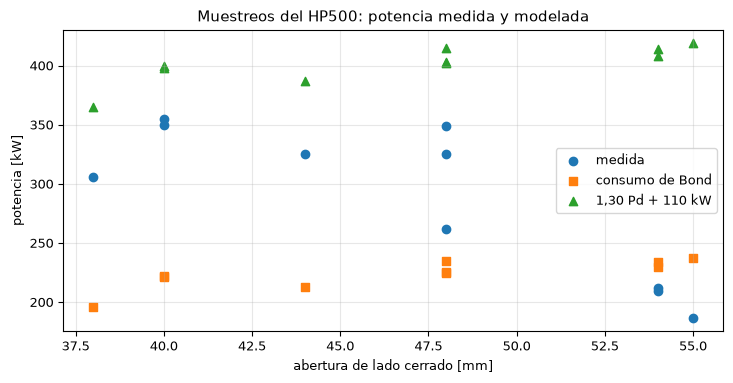

In [7]:
# Grafique la potencia medida y las dos modeladas contra la abertura
fig, ax = plt.subplots()
ax.scatter(css, measured_kw, label="medida", zorder=3)
ax.scatter(css, bare, marker="s", label="consumo de Bond")
ax.scatter(css, calibrated, marker="^", label="1,30 Pd + 110 kW")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("potencia [kW]")
ax.set_title("Muestreos del HP500: potencia medida y modelada")
ax.legend()
fig.tight_layout()
plt.show()

La figura muestra el resultado negativo directamente. La potencia medida baja al abrir la abertura, de 355 kW con 40 mm a 187 kW con 55 mm; las dos potencias modeladas se mantienen planas en una banda angosta, cerca de 200 a 240 kW para el consumo de Bond y de 360 a 420 kW para la forma calibrada, y la forma calibrada queda muy sobre cada punto medido. Un consumo de Bond plano no puede seguir una cantidad que se mueve con la abertura en un factor de dos: cerrar la abertura hace un producto más fino y sube los kWh por tonelada, mientras el menor tonelaje en toneladas lo cancela en el consumo de Bond, una cancelación que la potencia de la planta no muestra. El resultado no se esconde: las constantes de la forma del artículo pertenecen a la potencia específica por tamaño del propio artículo, no al consumo clásico de Bond usado aquí.

**Paso 4, la única comprobación de reproducción.** El pipeline escribe los resultados del motor en los diez muestreos en el documento de columna vertebral, y una prueba mantiene a los dos iguales. La celda reconstruye el documento desde los muestreos con el propio constructor del pipeline y lo compara, completo, con el archivo versionado.

In [8]:
# Reconstruya el documento de columna vertebral desde los muestreos y compárelo con el versionado
rebuilt = backbone.build(surveys, committed["engine_version"])
print("el documento reconstruido es igual al versionado:", rebuilt == committed)
print("muestreo 1 en el documento, tonelaje modelado [t/h]:", committed["surveys"][0]["backbone"]["throughput_tph"])

el documento reconstruido es igual al versionado: True
muestreo 1 en el documento, tonelaje modelado [t/h]: 1208.87


**Paso 5, qué cambia la calibración.** La vía calibrada reemplaza la clasificación sintética, el quiebre y la base de capacidad por el ajuste del artículo. La celda corre cada muestreo dos veces, con la vía calibrada y con la sintética en el mismo punto de operación, e imprime el promedio de los tres resultados sobre los diez muestreos para cada una.

In [9]:
# Corra cada muestreo en la vía calibrada y en la sintética y compare los resultados medios
from dataclasses import replace

pairs = [(r, evaluate(replace(operating_from_survey(s.css_mm, s.f80_mm), calibrated=False))) for r, s in zip(runs, surveys)]
for name, field in (("P80 [mm]", "p80"), ("throughput [t/h]", "throughput_tph"), ("power [kW]", "power_kw")):
    print(f"{name:18s} calibrated {np.mean([getattr(a, field) for a, _ in pairs]):7.1f}   synthetic {np.mean([getattr(b, field) for _, b in pairs]):7.1f}")

P80 [mm]           calibrated    29.7   synthetic    36.0
throughput [t/h]   calibrated  1088.0   synthetic   874.4
power [kW]         calibrated   401.1   synthetic   133.7


La calibración mueve el tonelaje en cerca de un cuarto, de una media cercana a 880 a una media cercana a 1090 t/h que coincide con la de la planta, y el P80 medio en varios milímetros. Mueve la potencia en un factor de tres, de un consumo de Bond cercano a 140 kW a la forma 1,30 Pd + 110 cercana a 400 kW, y ese es el movimiento que aleja al modelo de los 187 a 355 kW medidos: el desfase de 110 kW es mayor que el consumo de Bond de algunos muestreos. La calibración se ajustó al tamaño y a la capacidad, y la forma de potencia se trasplantó desde la potencia específica por tamaño del artículo a un consumo clásico de Bond al que nunca se ajustó.

**Paso 6, la energía específica.** Dividir la potencia por las toneladas da la energía por tonelada, la cantidad que optimiza una planta. El valor medido es la potencia sobre el flujo de alimentación medido, y el del modelo es la energía de Bond del oráculo para el F80 y el P80 del propio motor. La figura grafica ambas contra la abertura.

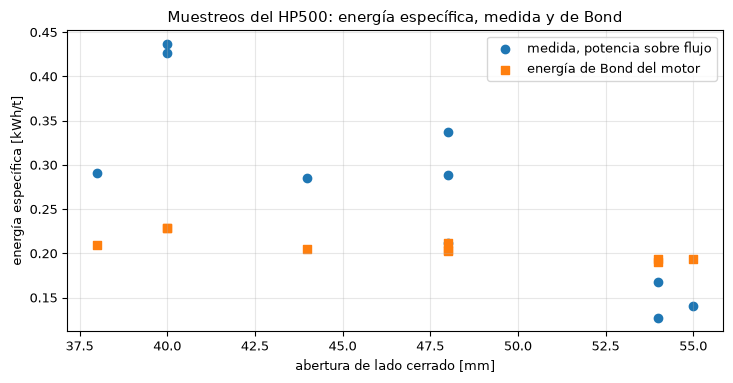

medida con 38 a 40 mm y con 54 a 55 mm [kWh/t]: [0.437 0.291 0.427] [0.128 0.167 0.14 ]
rango de la energía de Bond [kWh/t]: 0.19 0.229


In [10]:
# Energía específica medida frente a la energía de Bond del oráculo para el motor, por muestreo, contra la abertura
measured_kwh_t = measured_kw / measured_q
bond_kwh_t = np.array([bond_energy_kwh_t(r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs])
fig, ax = plt.subplots()
ax.scatter(css, measured_kwh_t, label="medida, potencia sobre flujo")
ax.scatter(css, bond_kwh_t, marker="s", label="energía de Bond del motor")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("energía específica [kWh/t]")
ax.set_title("Muestreos del HP500: energía específica, medida y de Bond")
ax.legend()
fig.tight_layout()
plt.show()
print("medida con 38 a 40 mm y con 54 a 55 mm [kWh/t]:", measured_kwh_t[css <= 40].round(3), measured_kwh_t[css >= 54].round(3))
print("rango de la energía de Bond [kWh/t]:", bond_kwh_t.min().round(3), bond_kwh_t.max().round(3))

La energía medida por tonelada se triplica al cerrar la abertura de 55 a 40 mm, de unos 0,13 a 0,14 kWh/t con 54 a 55 mm a 0,43 a 0,44 kWh/t con 40 mm (el muestreo 7, con 38 mm, es la excepción con 0,29), como corresponde a que un producto más fino pide más energía por tonelada; la energía de Bond del motor se mueve solo de 0,19 a 0,23 kWh/t. La energía de la planta es mucho más sensible a la abertura que la del modelo, que es el mismo hallazgo de la figura de potencia pero en las unidades que usa una planta. La razón de tamaños de Bond no produce un cambio de tres veces con un cambio de 15 mm de la abertura, de modo que la pieza que falta está en la ley de energía, no en la calibración de los tamaños.

## Resultados

**Respuesta:** el motor reproduce el tonelaje de la planta y no reproduce su potencia. Los diez muestreos pasan la compuerta de expectativas: tonelaje a menos de 29 por ciento, P80 entre 0,35 y 1,1 veces la abertura, razón de reducción entre 1,8 y 4. Los residuos de tonelaje tienen una media de -2,6 por ciento, ninguna tendencia organizada frente a la abertura ni al f80, y un error absoluto medio de 11,55 por ciento. La potencia no: los kW medidos bajan de 355 a 187 al abrir la abertura, el consumo de Bond se mueve solo entre 196 y 237 kW y tiene una correlación negativa con la medición, y la forma calibrada, con 47,58 por ciento de error absoluto medio, es la peor de las dos formas que ofrece el motor frente a un Bond puro de 26,88 por ciento. El documento de columna vertebral reconstruido es igual al versionado.

La primera figura muestra lo que el modelo deja sin explicar en el tonelaje, la segunda la potencia fallando a la planta. Un validador concluiría que el tonelaje es un éxito calibrado y parcial y la potencia un negativo honesto, que el producto informa y no esconde, que el P80 solo puede juzgarse con la relación del chancador atorado porque el artículo no entrega una tabla de él, y que todos estos números son dentro de la muestra, de modo que ninguno dice aún cómo se comporta el motor con un muestreo al que no se ajustó.

## Resumen

Con datos reales el tonelaje del motor pasa la compuerta y sigue la abertura, su potencia no sigue a la planta y el propio informe del producto lo dice, y cada número de este notebook es dentro de la muestra. El notebook siguiente de este tema corre el protocolo del estado del arte del artículo fuente, el ajuste dentro de la muestra, y muestra qué puede y qué no puede decir ese protocolo; el tema 06 luego retiene los muestreos.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193